DATASET MAHASISWA


,IPK,SKS,Lulus_Tepat_Waktu
0,3.80,140,Ya
1,3.50,130,Ya
2,3.20,120,Ya
3,2.90,100,Tidak
4,3.70,138,Ya
5,2.50,85,Tidak
6,3.40,125,Ya
7,2.70,95,Tidak
8,3.90,145,Ya
9,3.10,115,Ya


Jumlah data latih: 24
Jumlah data uji: 6

Model berhasil dilatih.

HASIL PREDIKSI


,IPK,SKS,Aktual,Prediksi
2,3.20,120,Ya,Ya
6,3.40,125,Ya,Ya
8,3.90,145,Ya,Ya
10,2.80,105,Tidak,Tidak
11,3.60,135,Ya,Ya
17,2.95,110,Tidak,Tidak



AKURASI MODEL: 100.0 %

LAPORAN KLASIFIKASI
              precision    recall  f1-score   support

       Tidak       1.00      1.00      1.00         2
          Ya       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

CONFUSION MATRIX
[[2 0]
 [0 4]]


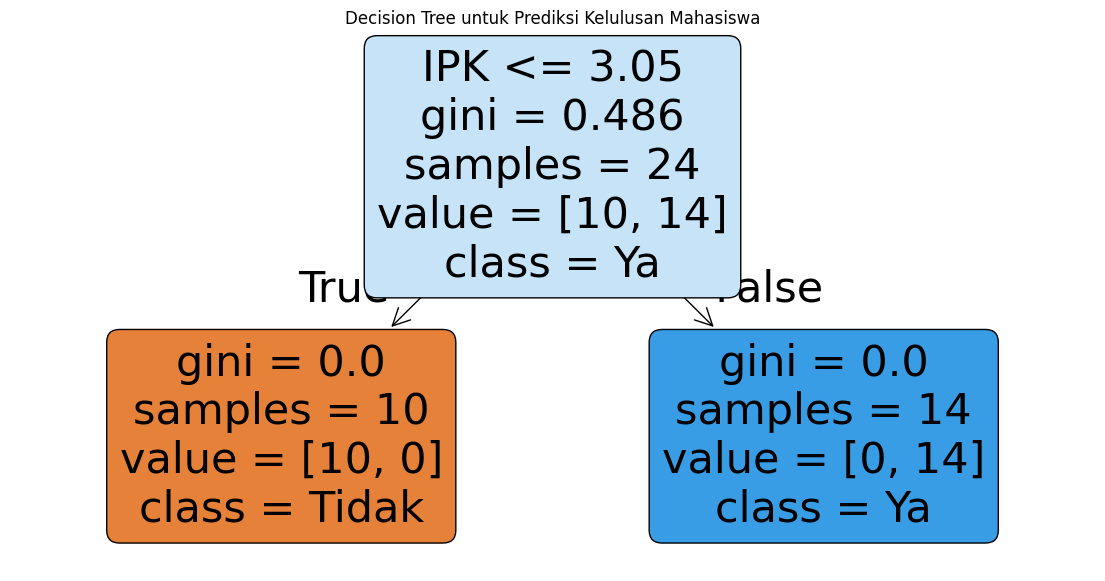


PREDIKSI MAHASISWA BARU
IPK: 3.45
Jumlah SKS: 125.0
Hasil prediksi: Ya

PROBABILITAS PREDIKSI
Tidak: 0.00%
Ya: 100.00%


In [1]:
# ==================================================
# PROYEK MACHINE LEARNING
# Prediksi Kelulusan Mahasiswa dengan Supervised Learning
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ==================================================
# 1. MEMBUAT DATASET SIMULASI
# ==================================================

data = {
    "IPK": [
        3.80, 3.50, 3.20, 2.90, 3.70,
        2.50, 3.40, 2.70, 3.90, 3.10,
        2.80, 3.60, 2.40, 3.30, 3.75,
        2.60, 3.45, 2.95, 3.85, 2.30,
        3.55, 3.00, 3.25, 2.75, 3.65,
        2.85, 3.95, 2.45, 3.35, 3.15
    ],
    "SKS": [
        140, 130, 120, 100, 138,
        85, 125, 95, 145, 115,
        105, 135, 80, 122, 140,
        90, 128, 110, 144, 75,
        132, 112, 118, 98, 136,
        108, 146, 82, 124, 116
    ],
    "Lulus_Tepat_Waktu": [
        "Ya", "Ya", "Ya", "Tidak", "Ya",
        "Tidak", "Ya", "Tidak", "Ya", "Ya",
        "Tidak", "Ya", "Tidak", "Ya", "Ya",
        "Tidak", "Ya", "Tidak", "Ya", "Tidak",
        "Ya", "Tidak", "Ya", "Tidak", "Ya",
        "Tidak", "Ya", "Tidak", "Ya", "Ya"
    ]
}

df = pd.DataFrame(data)

print("DATASET MAHASISWA")
display(df)

# ==================================================
# 2. MEMISAHKAN FITUR DAN TARGET
# ==================================================

X = df[["IPK", "SKS"]]
y = df["Lulus_Tepat_Waktu"]

# ==================================================
# 3. MEMBAGI DATA LATIH DAN DATA UJI
# ==================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

# ==================================================
# 4. MEMBANGUN MODEL MACHINE LEARNING
# ==================================================

model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel berhasil dilatih.")

# ==================================================
# 5. MELAKUKAN PREDIKSI DATA UJI
# ==================================================

y_pred = model.predict(X_test)

print("\nHASIL PREDIKSI")
hasil = X_test.copy()
hasil["Aktual"] = y_test
hasil["Prediksi"] = y_pred

display(hasil.sort_index())

# ==================================================
# 6. EVALUASI MODEL
# ==================================================

akurasi = accuracy_score(y_test, y_pred)

print("\nAKURASI MODEL:", round(akurasi * 100, 2), "%")

print("\nLAPORAN KLASIFIKASI")
print(classification_report(y_test, y_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["Tidak", "Ya"]
))

# ==================================================
# 7. VISUALISASI POHON KEPUTUSAN
# ==================================================

plt.figure(figsize=(14, 7))

plot_tree(
    model,
    feature_names=["IPK", "SKS"],
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree untuk Prediksi Kelulusan Mahasiswa")
plt.show()

# ==================================================
# 8. PREDIKSI MAHASISWA BARU
# ==================================================

mahasiswa_baru = pd.DataFrame({
    "IPK": [3.45],
    "SKS": [125]
})

prediksi = model.predict(mahasiswa_baru)

print("\nPREDIKSI MAHASISWA BARU")
print("IPK:", mahasiswa_baru.iloc[0]["IPK"])
print("Jumlah SKS:", mahasiswa_baru.iloc[0]["SKS"])
print("Hasil prediksi:", prediksi[0])

probabilitas = model.predict_proba(mahasiswa_baru)[0]

print("\nPROBABILITAS PREDIKSI")
for kelas, nilai in zip(model.classes_, probabilitas):
    print(f"{kelas}: {nilai * 100:.2f}%")